# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
from aitlas.datasets import AirbusShipDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir": "./data/airbus_ship_detection/train_v2",
    "csv_file": "./data/airbus_ship_detection/train_ship_segmentations_v2.csv"
}
dataset = AirbusShipDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 192555


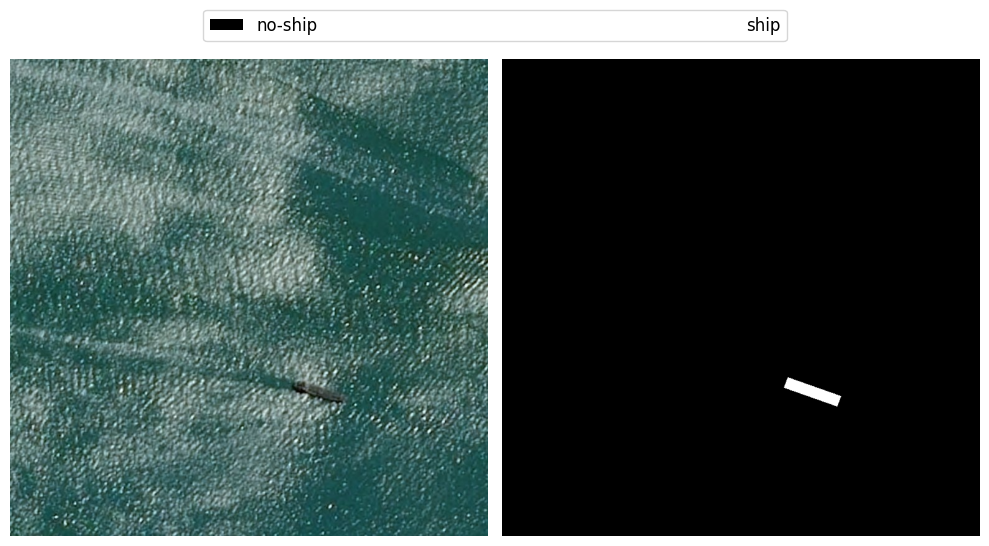

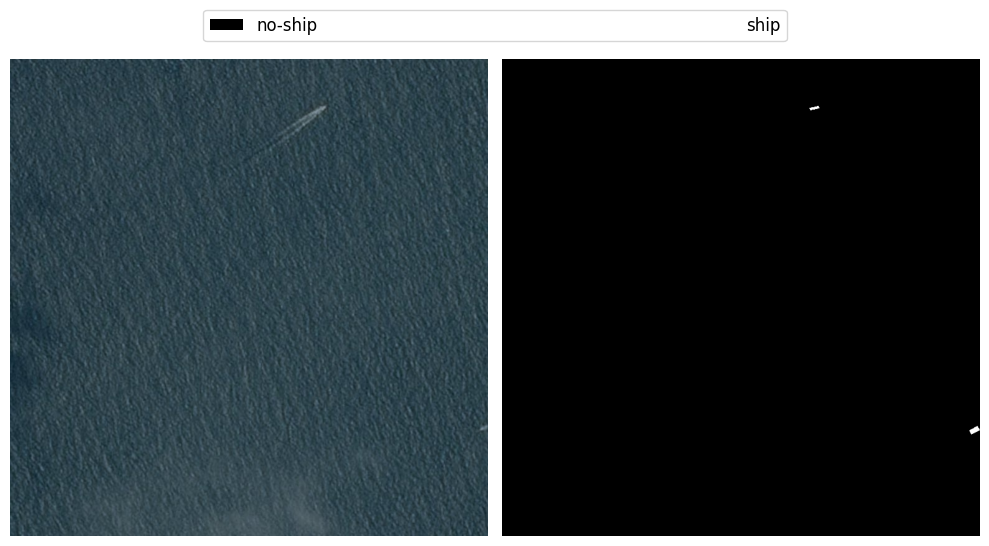

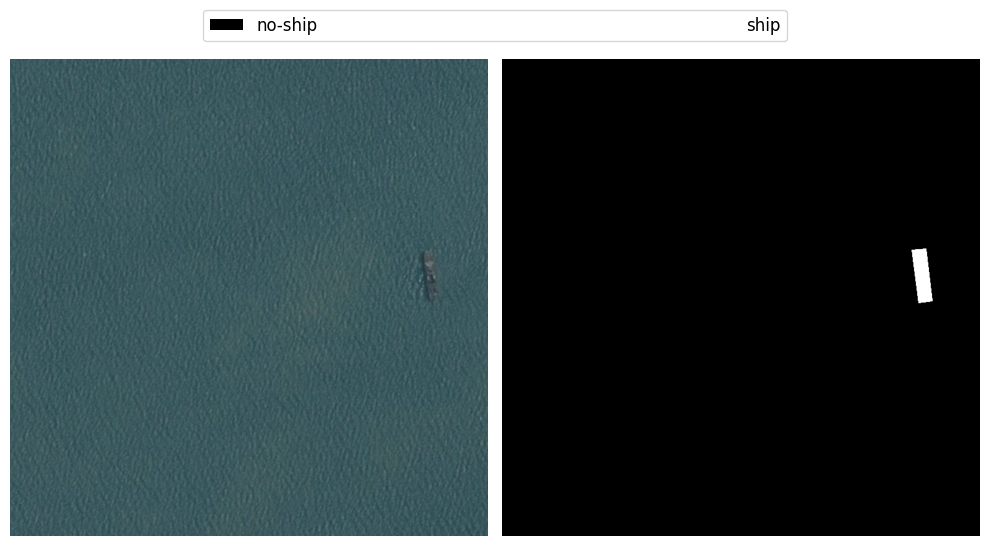

In [31]:
dataset.show_image(2)
dataset.show_image(30)
dataset.show_image(5000);

In [32]:
dataset.data_distribution_table()

,Number of pixels
no-ship,136547693889
ship,128092863


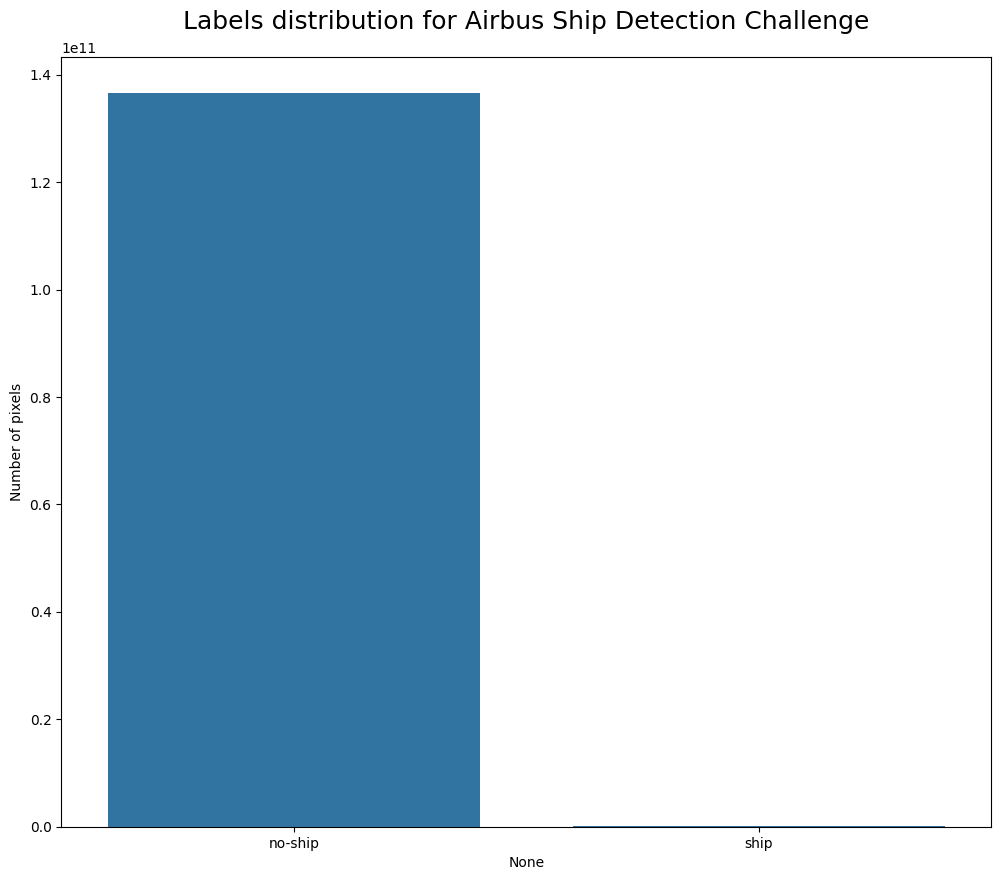

In [6]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/airbus_ship_detection/train_v2",
    "csv_file": "./data/airbus_ship_detection/train_ship_segmentations_v2.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = AirbusShipDataset(train_dataset_config)
len(train_dataset)

192555

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/airbus_ship_detection/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [35]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-10-07 09:11:11,716 INFO Starting training.
training: 100%|██████████| 12035/12035 [32:42<00:00,  6.13it/s]
2025-10-07 09:43:54,420 INFO epoch: 1, time: 1963, loss:  0.00934
testing on train set: 100%|██████████| 12035/12035 [26:33<00:00,  7.55it/s]
2025-10-07 10:10:29,188 INFO IOU:0.998726657579758, IOU mean:0.7541505016813601, IOU per Class:[0.99925486 0.50904615]
training: 100%|██████████| 12035/12035 [32:34<00:00,  6.16it/s]
2025-10-07 10:43:03,801 INFO epoch: 2, time: 1954, loss:  0.00048
testing on train set: 100%|██████████| 12035/12035 [26:19<00:00,  7.62it/s]
2025-10-07 11:09:23,075 INFO IOU:0.9534048954259172, IOU mean:0.5024405312210075, IOU per Class:[0.97654842 0.02833264]
training: 100%|██████████| 12035/12035 [32:03<00:00,  6.26it/s]
2025-10-07 11:41:26,862 INFO epoch: 3, time: 1923, loss:  0.00043
testing on train set: 100%|██████████| 12035/12035 [26:42<00:00,  7.51it/s]
2025-10-07 12:08:09,189 INFO IOU:0.9990109507156791, IOU mean:0.8219063214457429, IOU per Class

0.00031746462676622377

## Predictions ##

2025-10-08 06:43:15,350 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/airbus-ship-detection/checkpoint.pth.tar
2025-10-08 06:43:15,822 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/airbus-ship-detection/checkpoint.pth.tar at epoch 11


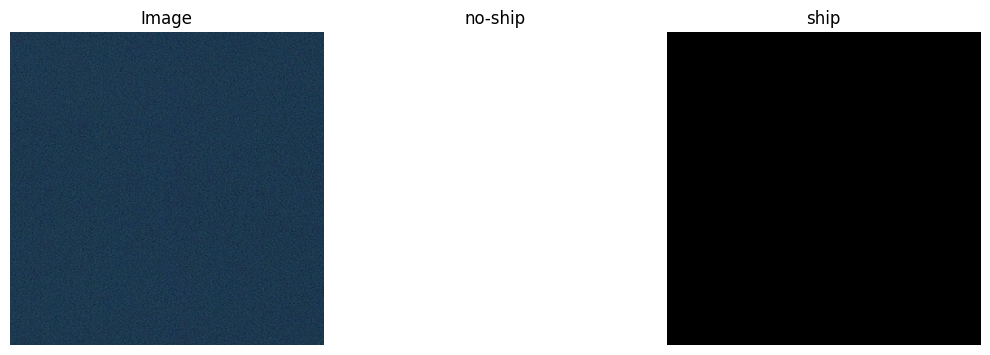

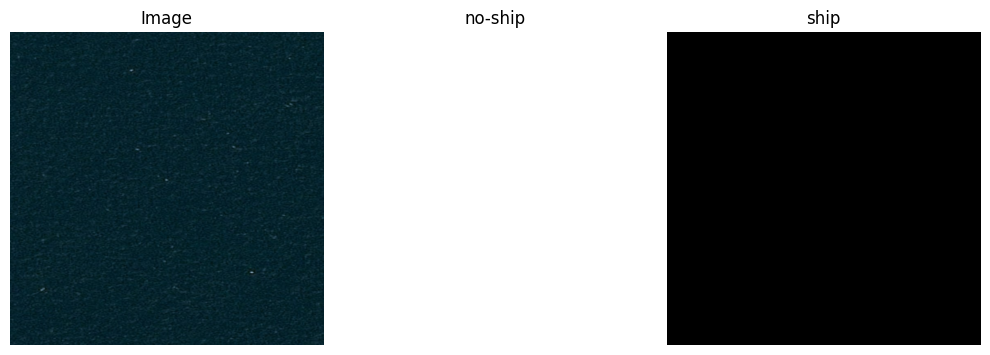

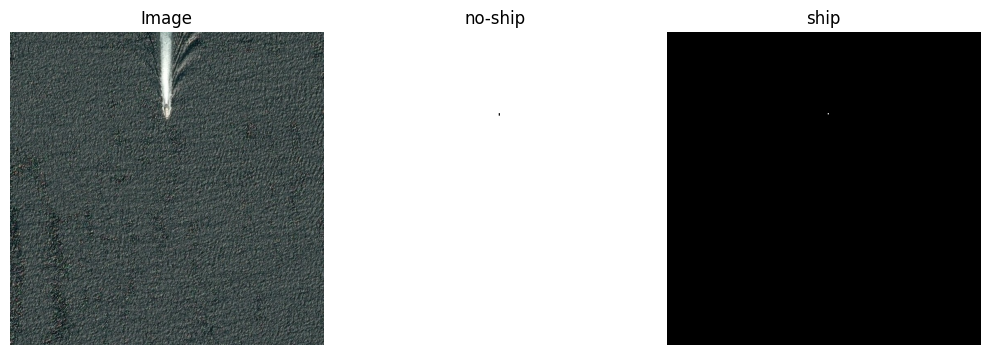

In [ ]:
model_path = "./data/experiments/airbus_ship_detection/checkpoint.pth.tar"
labels = ["no-ship","ship"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/airbus_ship_detection/test_v2/00a2aca2f.jpg')
fig = model.predict_masks(image, labels, transform)
image = image_loader('./data/airbus_ship_detection/test_v2/0a867ce5f.jpg')
fig = model.predict_masks(image, labels, transform)
image = image_loader('./data/airbus_ship_detection/test_v2/534e10e90.jpg')
fig = model.predict_masks(image, labels, transform)